# AI-Assisted Community Awareness Campaign Generator

## Phase 1: Dataset Exploration

Dataset: UNDP SDGi Corpus

Objective:
Explore the dataset, understand its structure,
identify data-quality issues, and prepare for
baseline SDG text-classification experiments.

1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from collections import Counter

print("Libraries imported successfully.")

Libraries imported successfully.


2. Load the dataset

In [5]:

dataset = load_dataset("UNDP/sdgi-corpus")

print(dataset)
print("Available splits:", list(dataset.keys()))


DatasetDict({
    train: Dataset({
        features: ['text', 'embedding', 'labels', 'metadata'],
        num_rows: 5880
    })
    test: Dataset({
        features: ['text', 'embedding', 'labels', 'metadata'],
        num_rows: 1470
    })
})
Available splits: ['train', 'test']


3. Convert to DataFrames

In [6]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

train_df.head()

Training shape: (5880, 4)
Testing shape: (1470, 4)


,text,embedding,labels,metadata
0,END POVERTY\r\nIN ALL ITS FORMS \r\nEVERYWHERE...,"[-0.0066694277, -0.0135167073, 0.0032988016000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
1,PONER FIN A LA POBREZA\r\nEN TODAS SUS FORMAS ...,"[-0.0120671522, -0.0182979926, 0.0129378373000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
2,End poverty in all its \r\nforms everywhere\r\...,"[-0.0063659865, -0.0047052945, 0.0053374511000...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
3,Poner fin a la pobreza\r\nen todas sus formas\...,"[-0.012985382200000001, -0.0147539768, 0.00048...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."
4,"15\r\nWith regard to this SDG in particular, i...","[-0.007488854200000001, -0.0136874933, 0.02816...",[1],"{'country': 'arg', 'file_id': 'sdg-01/vlr-repo..."


4. Inspect columns and data types

In [7]:
print("Columns:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nDataset information:")
train_df.info()

Columns:
['text', 'embedding', 'labels', 'metadata']

Data types:
text            str
embedding    object
labels       object
metadata     object
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   text       5880 non-null   str   
 1   embedding  5880 non-null   object
 2   labels     5880 non-null   object
 3   metadata   5880 non-null   object
dtypes: object(3), str(1)
memory usage: 49.0+ MB


5. Check missing values and duplicates

In [9]:
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate text records:")
print(train_df["text"].duplicated().sum())

print("\nDuplicate text records in test data:")
print(test_df["text"].duplicated().sum())

Missing values:
text         0
embedding    0
labels       0
metadata     0
dtype: int64

Duplicate text records:
0

Duplicate text records in test data:
0


6. Check overlap between training and test data

In [10]:
train_texts = set(train_df["text"].dropna())
test_texts = set(test_df["text"].dropna())

overlap = train_texts.intersection(test_texts)

print("Exact text overlap between train and test:", len(overlap))

Exact text overlap between train and test: 0


7. Examine sample records

In [11]:
for i in range(3):
    print(f"\nSAMPLE {i + 1}")
    print(train_df.iloc[i]["text"][:500])
    print("Labels:", train_df.iloc[i]["labels"])
    print("Metadata:", train_df.iloc[i]["metadata"])


SAMPLE 1
END POVERTY
IN ALL ITS FORMS 
EVERYWHERE

22
Poverty can be understood as a phenomenon that goes beyond monetary insu!ciency. A multidimensional 
conception of poverty takes into consideration minimum consumption of essential basic goods and 
services “as part of the set of opportunities that any society should o"er its members”. This set includes 
access to basic levels of education, health, housing and other services (Gasparini, 2012).
In addition, the services that transform cities int
Labels: [1]
Metadata: {'country': 'arg', 'file_id': 'sdg-01/vlr-report-arg-buenos_aires-2021-en-1.pdf', 'language': 'en', 'locality': 'buenos_aires', 'size': 'm', 'type': 'vlr', 'year': 2021}

SAMPLE 2
PONER FIN A LA POBREZA
EN TODAS SUS FORMAS 
EN TODO EL MUNDO

22
La pobreza puede ser entendida como un fenómeno que va más allá de la insuficiencia monetaria. Una 
concepción multidimensional de la pobreza toma en consideración consumos mínimos de bienes y ser￾vicios básicos esenciales “como 

8. Analyze languages

metadata
en    4225
es     935
fr     720
Name: count, dtype: int64


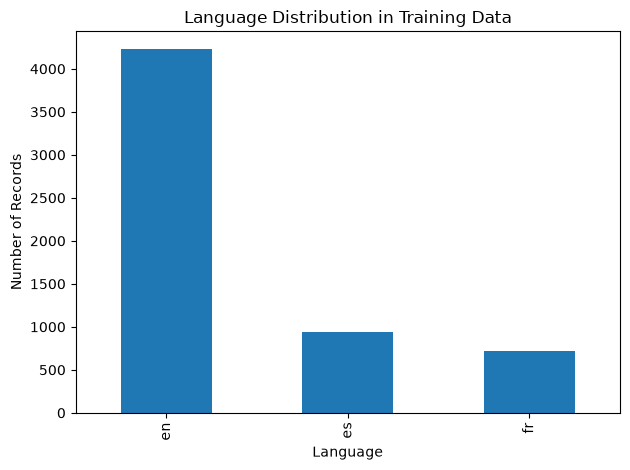

In [12]:
languages = train_df["metadata"].apply(
    lambda item: item.get("language")
)

print(languages.value_counts())

languages.value_counts().plot(
    kind="bar",
    title="Language Distribution in Training Data",
    xlabel="Language",
    ylabel="Number of Records"
)

plt.tight_layout()
plt.show()

9. Analyze label distribution

,Label,Count
0,1,452
1,2,437
2,3,578
3,4,532
4,5,487
5,6,395
6,7,420
7,8,548
8,9,467
9,10,485


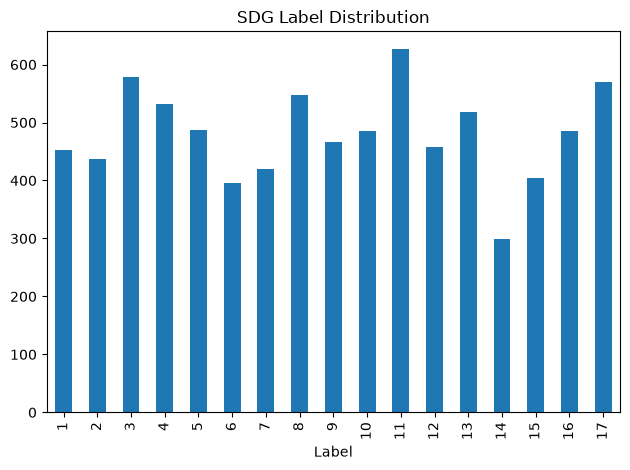

In [13]:
label_counts = Counter(
    label
    for labels in train_df["labels"]
    for label in labels
)

label_df = pd.DataFrame(
    label_counts.items(),
    columns=["Label", "Count"]
).sort_values("Label")

display(label_df)

label_df.plot(
    x="Label",
    y="Count",
    kind="bar",
    legend=False,
    title="SDG Label Distribution"
)

plt.tight_layout()
plt.show()

10. Analyze text length

count      5880.000000
mean       8584.092857
std        8172.927108
min         115.000000
25%        2534.000000
50%        6567.000000
75%       11997.250000
max      114745.000000
Name: text_length, dtype: float64


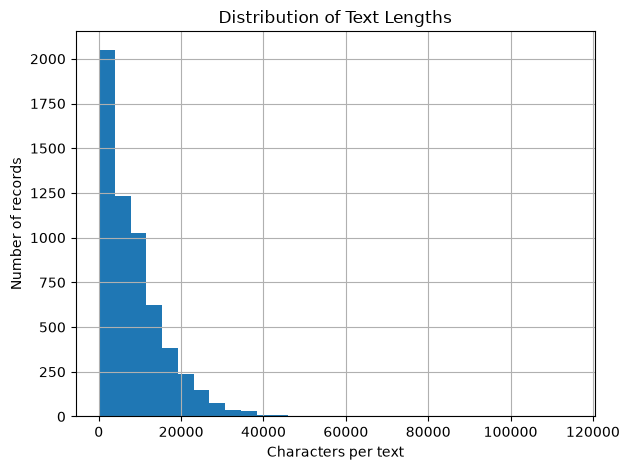

In [14]:
train_df["text_length"] = (
    train_df["text"]
    .fillna("")
    .astype(str)
    .str.len()
)

print(train_df["text_length"].describe())

train_df["text_length"].hist(bins=30)

plt.title("Distribution of Text Lengths")
plt.xlabel("Characters per text")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## Key Findings

1. Dataset size:
   Confirmed from the loaded training and test splits.

2. Missing values:
   Record the columns affected and their counts.

3. Duplicate records:
   Record the number found and whether further
   inspection is required.

4. Language distribution:
   Identify the dominant language and any imbalance.

5. Label distribution:
   Identify common and rare labels.

6. Text quality:
   Record any corrupted or unusually short examples.

7. Next steps:
   Decide on preprocessing and the appropriate
   multi-label classification strategy.